# Pulse Envelope API Tutorial

This notebook introduces MBLab's pulse API: normalized complex envelopes, carrier pulses, automatic ASAP scheduling, barriers, optional legacy conversion, and visualization. Time is expressed in seconds and frequency in hertz.


In [1]:
import matplotlib.pyplot as plt
import numpy as np

from mb_client.pulse import (
    Constant,
    Cos,
    Drag,
    Gaussian,
    Pulse,
    PulseSequence,
    PulseScheduler,
    DriveChannel,
    FluxChannel,
    ReadoutChannel,
)


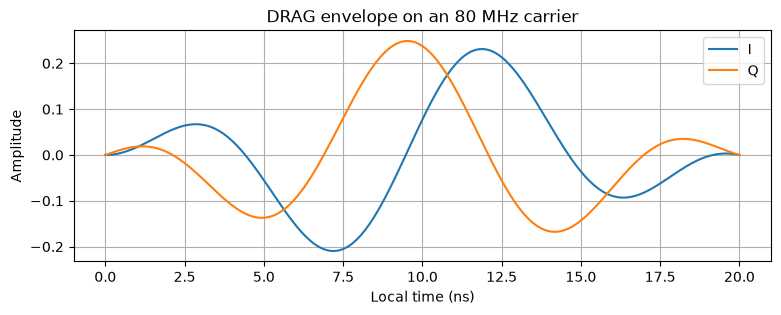

In [2]:
x90 = Pulse(
    Drag(duration=20e-9, amplitude=0.25, beta=-2),
    frequency=80e6,
    phase=0.0,
)
readout = Pulse(Constant(duration=80e-9, amplitude=0.15), frequency=50e6)
flux = Pulse(Constant(duration=40e-9, amplitude=0.1))

carrier_time = np.linspace(0, x90.duration, 301)
carrier_iq = x90.sample(carrier_time)
plt.figure(figsize=(9, 3))
plt.plot(carrier_time * 1e9, carrier_iq.real, label="I")
plt.plot(carrier_time * 1e9, carrier_iq.imag, label="Q")
plt.xlabel("Local time (ns)")
plt.ylabel("Amplitude")
plt.title("DRAG envelope on an 80 MHz carrier")
plt.grid(True)
plt.legend()


## Automatic scheduling on independent channels

A `PulseSequence` contains operations, not start times. The default scheduler uses deterministic ASAP scheduling. Pulses on free, independent channels start together; pulses on the same channel are serialized. Literal `(channel, pulse)` tuples are shorthand for `sequence.play(channel, pulse)`.

In [3]:
parallel_sequence = PulseSequence([
    (DriveChannel(0), x90),
    (DriveChannel(1), x90),
    (DriveChannel(0), x90),
    (FluxChannel(0), flux),
])
parallel_schedule = PulseScheduler().schedule(parallel_sequence)

for entry in parallel_schedule:
    print(
        f"{str(entry.channel):6s} start={entry.start * 1e9:5.1f} ns "
        f"end={entry.end * 1e9:5.1f} ns"
    )


DriveChannel(0) start=  0.0 ns end= 20.0 ns
DriveChannel(1) start=  0.0 ns end= 20.0 ns
DriveChannel(0) start= 20.0 ns end= 40.0 ns
FluxChannel(0) start=  0.0 ns end= 40.0 ns


Text(0.5, 0.98, 'ASAP schedule on independent channels')

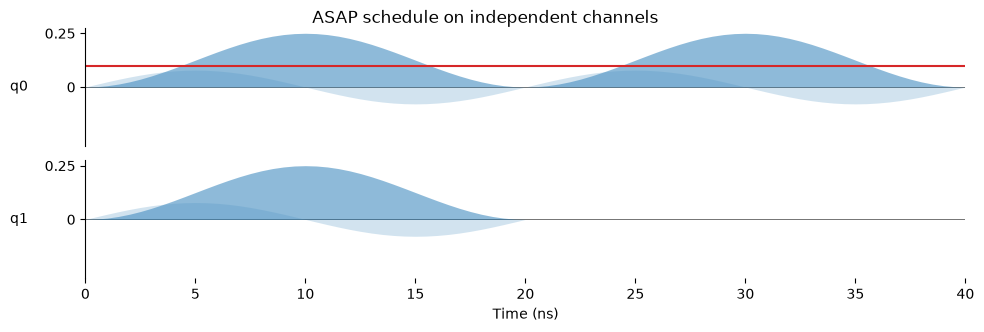

In [4]:
fig, axes = parallel_schedule.draw(sample_rate=2e9)
fig.suptitle("ASAP schedule on independent channels")


The two XY channels and the Z channel initially start at zero. The second `q0.xy` pulse waits for the first `q0.xy` pulse because they share a channel.

## Delays and selected-channel barriers

A delay advances one channel without generating waveform samples. A barrier over selected channels moves all of them to the latest availability among that set. Channels not named by the barrier remain independent.

In [5]:
selected_barrier_sequence = PulseSequence()
selected_barrier_sequence.play(DriveChannel(0), x90)
selected_barrier_sequence.delay(DriveChannel(1), 10e-9)
selected_barrier_sequence.play(DriveChannel(1), x90)
selected_barrier_sequence.play(ReadoutChannel(2), readout)
selected_barrier_sequence.barrier(DriveChannel(0), DriveChannel(1))
selected_barrier_sequence.play(DriveChannel(0), x90)
selected_barrier_sequence.play(DriveChannel(1), x90)

selected_schedule = selected_barrier_sequence.schedule()
for entry in selected_schedule:
    print(f"{str(entry.channel):6s}: {entry.start * 1e9:5.1f}--{entry.end * 1e9:5.1f} ns")


DriveChannel(0):   0.0-- 20.0 ns
DriveChannel(1):  10.0-- 30.0 ns
ReadoutChannel(2):   0.0-- 80.0 ns
DriveChannel(0):  30.0-- 50.0 ns
DriveChannel(1):  30.0-- 50.0 ns


Text(0.5, 0.98, 'Delay and selected-channel barrier')

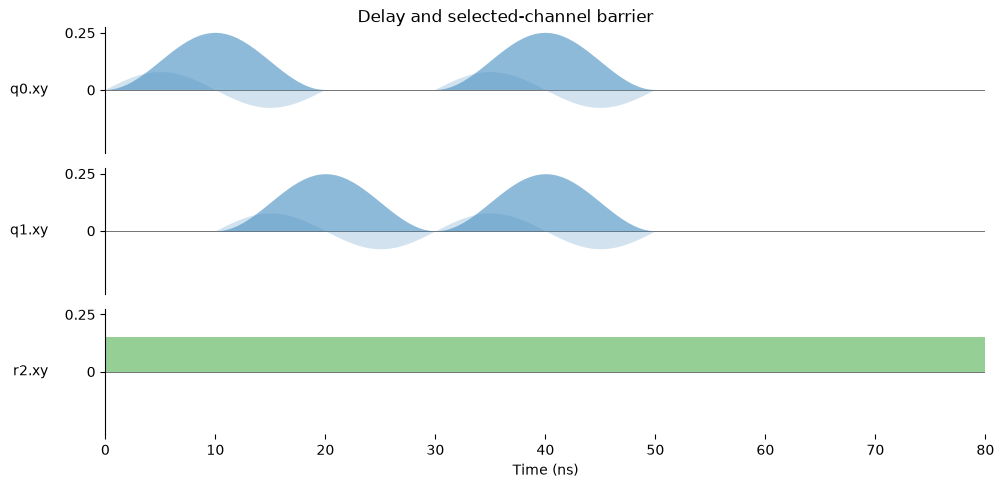

In [6]:
fig, axes = selected_schedule.draw(
    sample_rate=2e9,
    group_channel=False,
)
fig.suptitle("Delay and selected-channel barrier")


## Global barriers

Calling `barrier()` without channel arguments synchronizes every channel used so far. This is useful before a stage that must begin only after all preceding control pulses finish.

Text(0.5, 0.98, 'Global barrier')

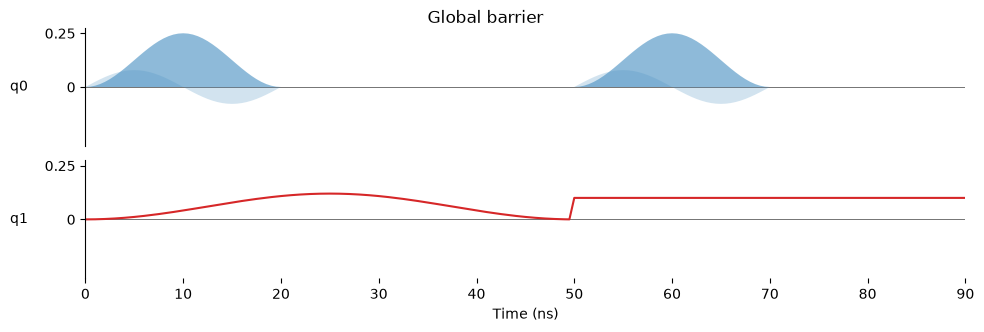

In [7]:
global_barrier_sequence = PulseSequence()
global_barrier_sequence.play(DriveChannel(0), x90)
global_barrier_sequence.play(FluxChannel(1), Pulse(Cos(50e-9, amplitude=0.12)))
global_barrier_sequence.barrier()
global_barrier_sequence.play(DriveChannel(0), x90)
global_barrier_sequence.play(FluxChannel(1), flux)

global_schedule = global_barrier_sequence.schedule()
assert global_schedule[2].start == 50e-9
assert global_schedule[3].start == 50e-9

fig, axes = global_schedule.draw(sample_rate=2e9)
fig.suptitle("Global barrier")


## Visualizing selected channels and custom time points

By default, `draw()` groups the XY, Z, and readout channels of each qubit on one subplot. Pass `group_channel=False` for one subplot per channel. Z pulses are real-only, so their Q component is validated but not drawn. The plots intentionally have no I/Q legends: solid lines are I and dashed lines are Q. `draw()` can also restrict the view to chosen channels and accept an explicit absolute-time array instead of generating one from `sample_rate`.


Text(0.5, 0.98, 'Selected channel')

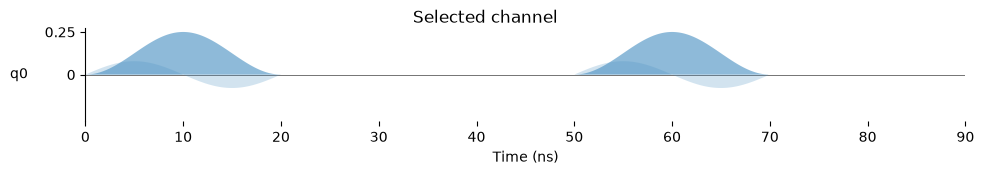

In [8]:
plot_time = np.linspace(0, global_schedule.duration, 501)
fig, axes = global_schedule.draw(t=plot_time, channels=[DriveChannel(0)])
fig.suptitle("Selected channel")
